In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

from sklearn.dummy import DummyClassifier

In [ ]:
data = load_breast_cancer(as_frame=True)

df = data.frame

print(df.head())

print("Dataset Shape:", df.shape)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [ ]:
X = df.drop('target', axis=1)

y = (df['target'] == 0).astype(int)

print(X.head())
print(y.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [ ]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

target
0    357
1    212
Name: count, dtype: int64


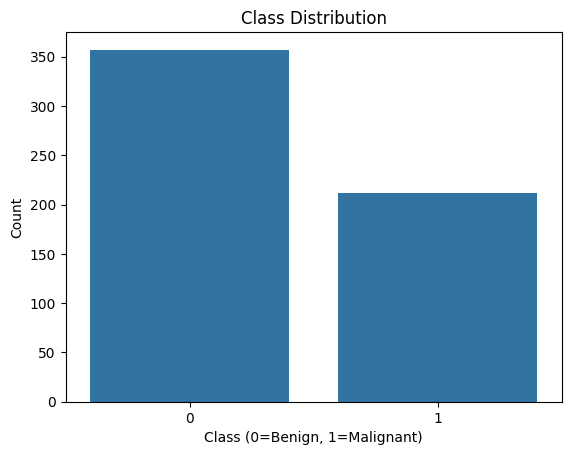

In [ ]:
print(y.value_counts())

sns.countplot(x=y)

plt.title("Class Distribution")
plt.xlabel("Class (0=Benign, 1=Malignant)")
plt.ylabel("Count")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Shape: (455, 30)
Testing Shape: (114, 30)

Training Class Distribution:
target
0    285
1    170
Name: count, dtype: int64

Testing Class Distribution:
target
0    72
1    42
Name: count, dtype: int64


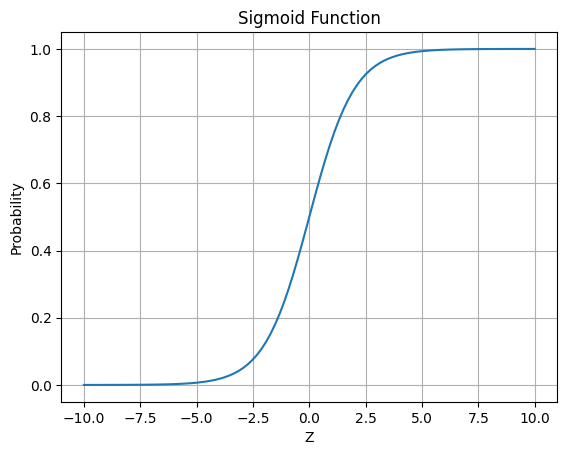

In [ ]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Z")
plt.ylabel("Probability")

plt.grid()
plt.show()

In [ ]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

model.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
lr = model.named_steps['logisticregression']

print("Intercept:", lr.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_[0]
})

print(coefficients)

Intercept: [-0.24300533]
                    Feature  Coefficient
0               mean radius     0.361150
1              mean texture     0.482219
2            mean perimeter     0.353160
3                 mean area     0.439950
4           mean smoothness     0.350622
5          mean compactness    -0.439546
6            mean concavity     0.782298
7       mean concave points     0.952813
8             mean symmetry    -0.163991
9    mean fractal dimension    -0.080865
10             radius error     1.233325
11            texture error    -0.407611
12          perimeter error     0.748295
13               area error     0.909029
14         smoothness error     0.247991
15        compactness error    -0.906925
16          concavity error    -0.092341
17     concave points error     0.482089
18           symmetry error    -0.330658
19  fractal dimension error    -0.593876
20             worst radius     0.896968
21            worst texture     1.434093
22          worst perimeter     

In [ ]:
probabilities = model.predict_proba(X_test)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

result = pd.DataFrame({
    'Actual': y_test.values,
    'Probability': probabilities,
    'Predicted': predictions
})

print(result.head(10))

   Actual  Probability  Predicted
0       0     0.000365          0
1       1     1.000000          1
2       0     0.042568          0
3       1     0.576187          1
4       0     0.509155          1
5       0     0.000616          0
6       1     0.761534          1
7       0     0.001012          0
8       0     0.000569          0
9       0     0.010768          0


Confusion Matrix:
[[71  1]
 [ 3 39]]


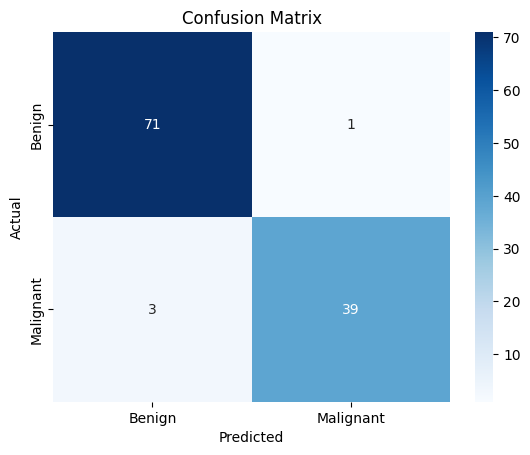

In [ ]:
cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, predictions)

precision = precision_score(y_test, predictions, zero_division=0)

recall = recall_score(y_test, predictions, zero_division=0)

specificity = tn / (tn + fp)

f1 = f1_score(y_test, predictions, zero_division=0)

roc_auc = roc_auc_score(y_test, probabilities)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
Specificity: 0.9861111111111112
F1 Score: 0.9512195121951219
ROC-AUC: 0.996031746031746


In [ ]:
print(classification_report(
    y_test,
    predictions,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [ ]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, predictions))

Baseline Accuracy: 0.631578947368421
Logistic Regression Accuracy: 0.9649122807017544


In [ ]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:

    pred = (probabilities >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted Positive': sum(pred),
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Predicted Positive  Accuracy  Precision    Recall  F1 Score
0        0.3                  42  0.982456    0.97619  0.976190   0.97619
1        0.5                  40  0.964912    0.97500  0.928571   0.95122
2        0.7                  38  0.964912    1.00000  0.904762   0.95000


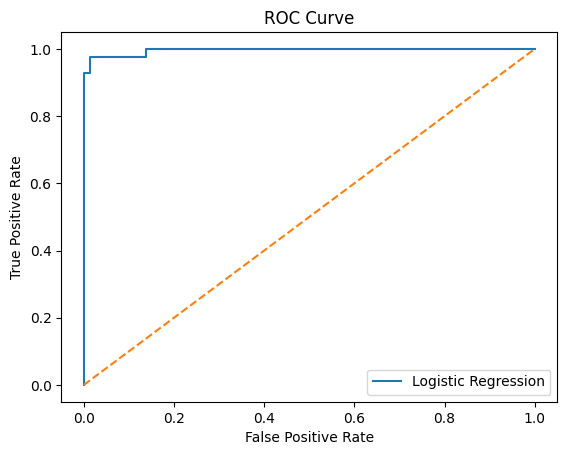

ROC-AUC: 0.996031746031746


In [ ]:
fpr, tpr, thresholds_roc = roc_curve(y_test, probabilities)

plt.plot(fpr, tpr, label='Logistic Regression')

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

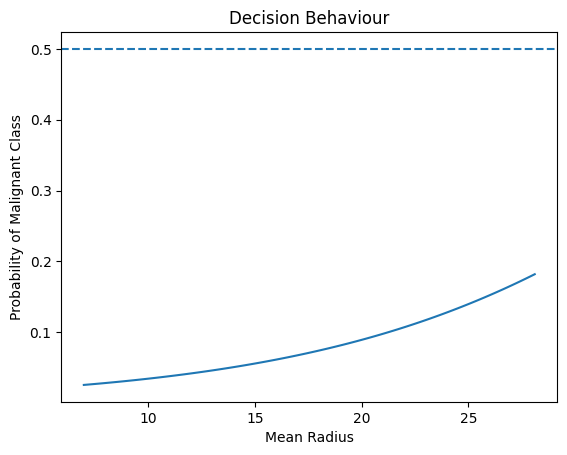

In [ ]:
feature = 'mean radius'

values = np.linspace(
    X_train[feature].min(),
    X_train[feature].max(),
    100
)

new_data = pd.DataFrame(
    np.tile(X_train.median().values, (100, 1)),
    columns=X.columns
)

new_data[feature] = values

prob = model.predict_proba(new_data)[:, 1]

plt.plot(values, prob)

plt.axhline(0.5, linestyle='--')

plt.xlabel("Mean Radius")
plt.ylabel("Probability of Malignant Class")

plt.title("Decision Behaviour")

plt.show()

In [ ]:
new_example = pd.DataFrame(
    [X_train.median().values],
    columns=X.columns
)

new_probability = model.predict_proba(new_example)[0, 1]

new_class = int(new_probability >= 0.5)

print("Predicted Probability:", new_probability)

print("Predicted Class:", new_class)

if new_class == 1:
    print("Predicted Class: Malignant")
else:
    print("Predicted Class: Benign")

Predicted Probability: 0.047635125105857275
Predicted Class: 0
Predicted Class: Benign


### Dataset Source

**Dataset Name:** Breast Cancer Wisconsin Dataset

**Source:** Scikit-learn

**Dataset Link:** [Breast Cancer Dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)

**Total Records:** 569

**Total Features:** 30

**Target Classes:**
- 0 – Benign
- 1 – Malignant